# DreaMS embeddings and molecular families

**Context.** PRIORITY project (WUR). Meeting with Joana Tirana and Daniel Probst on 19 Oct 2026: embeddings for metabolomics, molecular families, and the DreaMS paper (Bushuiev et al., *Nature Biotechnology*, 2025).
**Author:** Vitória Maia

**Questions.** Do DreaMS embeddings of MS/MS spectra put metabolites of the same molecular family close together? Does DreaMS similarity follow chemical structure better than the modified cosine that GNPS uses, and better than MS2DeepScore? As a first look towards federated learning: how different are the labs, and does a small layer trained across labs help?

**Steps**
0. Check that our DreaMS installation reproduces the numbers of the DreaMS networking tutorial.
1. Take six public GNPS molecular networking jobs on actinobacteria registered in the Paired Omics Data Platform.
2. Keep the spectra that pass DreaMS's own format A check, unchanged (the *protocol* variant). Our earlier cleaning is kept as a sensitivity analysis (*all_kept*).
3. Compute embeddings with the **pre-trained** DreaMS and MS2DeepScore models.
4. **Experiment A:** neighbours and a DreaMS network vs the GNPS molecular families.
5. **Experiment B:** spectral similarities vs structural similarity (Morgan Tanimoto and MHFP) on library-annotated spectra.
6. **Experiment C (prototype):** a small layer on frozen DreaMS embeddings, trained locally, centrally, with FedAvg and SplitFedV2-like, one lab per client.
7. **Experiment D:** can a classifier tell the labs apart from their embeddings?
8. Which public datasets could test DreaMS for genome-metabolome linking?

Each step is a script in `scripts/`. The notebook runs them and shows the results. `RESULTS.md` has the numbers of A and B in one page.

## 0. Setup

**One-time steps** (in a terminal, inside `priority-wur/dreams_molecular_families`). DreaMS and MS2DeepScore pin different package versions, so each gets its own Python 3.11 environment, made with [uv](https://docs.astral.sh/uv/):
```
git clone https://github.com/pluskal-lab/DreaMS.git .DreaMS
git -C .DreaMS checkout dbec3a0b514a99e5056cfccde4559fda8cfe8129
uv venv .dreams_env --python 3.11
uv pip install --python .dreams_env/Scripts/python.exe -e ./.DreaMS mhfp==1.9.6 ipykernel nbclient
uv venv .ms2ds_env --python 3.11
uv pip install --python .ms2ds_env/Scripts/python.exe "ms2deepscore>=2.6" onnxruntime
```
(On Mac/Linux, use `bin/python` instead of `Scripts/python.exe`.) The first runs download the DreaMS weights (2.6 GB, Hugging Face) and the MS2DeepScore model (416 MB, Zenodo). These folders are git-ignored.

**Data.** The GNPS jobs come from `data/raw/gnps/`, which `python -I scripts/download_data.py gnps` fills (run from the repository root).

**Kernel.** Any Jupyter kernel with pandas works: the steps always run with the Python of the right environment.

In [1]:
import importlib.util
import os
import subprocess
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RUNS = ["duncan_salinispora", "crusemann_salstrep", "crusemann_streptomyces",
        "chevrette_insect", "dorrestein_salbus", "tahlan_streptomyces"]
VARIANTS = ["protocol", "all_kept"]
RESULTS_DIR = {"protocol": "results", "all_kept": "results_all_kept"}

EXPERIMENT_DIR = Path.cwd()
if not (EXPERIMENT_DIR / "scripts" / "common.py").exists():
    raise RuntimeError("Open this notebook from the dreams_molecular_families folder.")


def env_python(name):
    path = EXPERIMENT_DIR / name / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    if not path.exists():
        raise RuntimeError(f"{name} not found. Do the one-time steps in section 0.")
    return str(path)


# Python used for the steps: this kernel if it has DreaMS, otherwise .dreams_env.
PY = sys.executable if importlib.util.find_spec("dreams") is not None else env_python(".dreams_env")
PY_MS2DS = env_python(".ms2ds_env")
print("DreaMS steps:", PY)
print("MS2DeepScore steps:", PY_MS2DS)


def step(script, *args, python=None, show=False, allow_fail=False):
    # Run one script and stop with its error message if it fails.
    start = time.time()
    result = subprocess.run(
        [python or PY, f"scripts/{script}", *args], capture_output=True, text=True,
        encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"},
    )
    if result.returncode != 0:
        if allow_fail:
            print(f"skipped: {script} {' '.join(args)}: {result.stdout.strip().splitlines()[-1:] or result.stderr[-300:]}")
            return
        print(result.stdout[-5000:], result.stderr[-5000:], sep="\n")
        raise RuntimeError(f"{script} {' '.join(args)} failed. Read the error above.")
    if show:
        print(result.stdout)
    print(f"done: {script} {' '.join(args)} ({time.time() - start:.0f} s)")


def results(run, name, variant="protocol"):
    return pd.read_parquet(EXPERIMENT_DIR / "runs" / run / RESULTS_DIR[variant] / f"{name}.parquet")


def side_by_side(name, key="metric", value="value", variant="protocol"):
    # One summary table per run, merged into one table with a column per run.
    tables = []
    for run in RUNS:
        path = EXPERIMENT_DIR / "runs" / run / RESULTS_DIR[variant] / f"{name}.parquet"
        if path.exists():
            tables.append(pd.read_parquet(path).set_index(key)[value].rename(run))
    return pd.concat(tables, axis=1).fillna("")


pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 200)

DreaMS steps: C:\Users\iraci\github-Victoria125\priority-wur\dreams_molecular_families\.dreams_env\Scripts\python.exe
MS2DeepScore steps: C:\Users\iraci\github-Victoria125\priority-wur\dreams_molecular_families\.ms2ds_env\Scripts\python.exe


## 0b. Does our DreaMS installation reproduce a published result?

Before comparing DreaMS with other methods, we check our setup against the DreaMS networking tutorial, which the DreaMS authors ran and saved with its outputs. It uses one public file (S_N1.mzML, MassIVE MSV000086206) and reports 3,809 spectra, a DreaMS similarity of 0.9109248 between spectra 1137 and 1165, and 6,858 edges in the DreaMS k-NN network. The script follows the tutorial code exactly, so none of our own processing is involved.

In [2]:
reproduction = EXPERIMENT_DIR / "reproduction" / "dreams_networking_tutorial.json"
if not reproduction.exists():
    step("reproduce_dreams_tutorial.py")
display(pd.read_json(reproduction, typ="series"))

expected (DreaMS tutorial)             {'spectra': 3809, 'pair_similarity': 0.9109248, 'network_edges': 6858}
pair                                                                                             [1137, 1165]
got (this machine)            {'spectra': 3809, 'pair_similarity': 0.9109244999999999, 'network_edges': 6858}
match                                       {'spectra': True, 'pair_similarity': True, 'network_edges': True}
reproduced                                                                                               True
seconds                                                                                                  1896
dreams_commit                                                        dbec3a0b514a99e5056cfccde4559fda8cfe8129
computed_on                                                                               2026-11-09T17:02:21
dtype: object

## 1. Data and the two versions of the input spectra

| Run | Dataset | MassIVE (PoDP) | GNPS fragment tolerance |
|---|---|---|---|
| `duncan_salinispora` | *Salinispora*, Duncan et al. 2015 (ion trap). Example job of the NPLinker docs | MSV000079284 | 0.3 Da |
| `crusemann_salstrep` | *Salinispora* + *Streptomyces*, Crüsemann et al. 2017 | MSV000078836 | 0.5 Da |
| `crusemann_streptomyces` | *Streptomyces*, Crüsemann et al. 2017 | MSV000078839 | 0.5 Da |
| `chevrette_insect` | Insect-associated actinobacteria, Chevrette et al. 2019 | MSV000084723 | 0.02 Da |
| `dorrestein_salbus` | *Streptomyces albus* J1074, Dorrestein lab | MSV000079519 | 0.01 Da |
| `tahlan_streptomyces` | Clavulanic acid producing *Streptomyces*, Tahlan lab | MSV000083835 | 0.02 Da |

All are GNPS jobs that the Paired Omics Data Platform links to genomes. The two Crüsemann jobs overlap: the SalStrep job also re-analyses MSV000078839.

**Molecular families.** GNPS connects two spectra when their modified cosine is high enough. Each connected group is a molecular family (`componentindex`). Spectra without connections are singletons.

**Checks.** `prepare_data.py` stops if the spectra with peaks are not exactly the network nodes, or if edges or library hits point to unknown nodes. `check_provenance.py` reads the input files listed in each GNPS job (`upload_file_mapping`) and checks that they come from the documented MassIVE datasets: the Duncan job reads its files from MSV000079484, a second deposit of the same study (all 50 file names are also in MSV000079284), and the Crüsemann SalStrep job combines *Salinispora* files uploaded from the submitter's workspace (84% of the names are in MSV000078836) with *Streptomyces* files from MSV000078839.

**Charge.** The charge that GNPS gives is kept in the MGF files; when it is unknown (0) the `CHARGE` line is left out. DreaMS's own check skips the charge test for unknown charges, and neither DreaMS nor MS2DeepScore uses the charge.

**Two versions of the input spectra.**
- `protocol` (main): only the spectra that pass DreaMS's own format A check (`DataFormatA().val_spec`: charge +1, precursor and fragments at most m/z 1000, 3 to 128 peaks, at least 3 peaks above 10% intensity, max/min intensity at least 20), given to every method exactly as GNPS gives them.
- `all_kept` (sensitivity analysis): our first cleaning. It removes the peaks above the precursor *before* applying the same rules, so it also keeps spectra that DreaMS's own check rejects: old ion trap data in the Duncan job (fragments heavier than the precursor, which is noise), and noise above m/z 1000 in every spectrum of the Crüsemann *Streptomyces* job. That job has no `protocol` spectra.

In [3]:
for run in RUNS:
    step("prepare_data.py", "--run", run)
step("check_provenance.py", show=True)

info = pd.DataFrame({run: pd.read_json(EXPERIMENT_DIR / "runs" / run / "run_info.json", typ="series") for run in RUNS})
display(info.drop([i for i in info.index if "md5" in i or i == "run"]))
display(pd.concat({run: pd.read_parquet(EXPERIMENT_DIR / "runs" / run / "input_report.parquet").set_index("step")["spectra"]
                   for run in RUNS}, axis=1).fillna(""))
display(Markdown((EXPERIMENT_DIR / "provenance" / "RESULTS_provenance.md").read_text(encoding="utf-8")))

done: prepare_data.py --run duncan_salinispora (8 s)


done: prepare_data.py --run crusemann_salstrep (7 s)


done: prepare_data.py --run crusemann_streptomyces (11 s)


done: prepare_data.py --run chevrette_insect (5 s)


done: prepare_data.py --run dorrestein_salbus (5 s)


done: prepare_data.py --run tahlan_streptomyces (7 s)


ok   duncan_salinispora: MSV000079484 (50 files, 100% found in MSV000079284)
ok   crusemann_salstrep: workspace:mcruesemann (432 files, 84% found in MSV000078836); MSV000078839 (243 files, 100% found in MSV000078839)
ok   crusemann_streptomyces: MSV000078839 (360 files, 100% found in MSV000078839)
ok   chevrette_insect: MSV000084723 (122 files, 100% found in MSV000084723)
ok   dorrestein_salbus: MSV000079519 (7 files, 100% found in MSV000079519)
ok   tahlan_streptomyces: MSV000083835 (95 files, 100% found in MSV000083835)

done: check_provenance.py  (1 s)


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
GNPS edges between these spectra (all_kept),289,4329,1695,1075,2670,8067
GNPS edges between these spectra (protocol),88,3902,NaN,903,2655,8047
GNPS families (size >= 2) (all_kept),20,299,148,100,193,1029
GNPS families (size >= 2) (protocol),13,282,NaN,97,193,1027
GNPS network edges,397,6750,2542,1644,4393,12521
GNPS task,c22f44b14a3d450eb836d607cb9521bb,9360fa514804487a9d39b7e7d7e6d514,840eadb054f74d74ae42152a08ed9628,927974dc1fe640d081b1467464815efa,7e463ca89a7c41958a0d0b993ee52131,b5eb34985777438aaf0f87e31889384c
GNPS workflow,METABOLOMICS-SNETS,METABOLOMICS-SNETS,METABOLOMICS-SNETS-V2,METABOLOMICS-SNETS-V2,METABOLOMICS-SNETS-V2,METABOLOMICS-SNETS-V2
MassIVE dataset (PoDP),MSV000079284,MSV000078836,MSV000078839,MSV000084723,MSV000079519,MSV000083835
MassIVE datasets in the GNPS job,MSV000079484,MSV000078839,MSV000078839,MSV000084723,MSV000079519,MSV000083835
dataset,"Salinispora, Duncan et al. 2015","Salinispora (MSV000078836) + Streptomyces (MSV000078839), Crüsemann et al. 2017","Streptomyces, Crüsemann et al. 2017","Insect-associated actinobacteria, Chevrette et al. 2019","Streptomyces albus J1074, Dorrestein lab","Clavulanic acid producing Streptomyces, Tahlan lab"


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
step,,,,,,
read from GNPS,25935.0,124950.0,433081.0,3117.0,4707.0,26065.0
removed: no peaks below the precursor m/z (looks like noise),9966.0,,,,,
removed: intensity range too small (max/min < 20),9477.0,1542.0,52.0,290.0,1396.0,1519.0
removed: fewer than 3 peaks above 10% intensity,2404.0,395.0,285.0,55.0,533.0,1392.0
removed: charge is not +1,1074.0,532.0,416.0,,657.0,776.0
removed: precursor m/z above 1000,111.0,92.0,108.0,44.0,68.0,129.0
kept by our cleaning (all_kept),2903.0,3685.0,1973.0,825.0,2053.0,8903.0
"pass DreaMS's own check, unchanged (protocol)",528.0,3445.0,0.0,785.0,2392.0,8901.0
removed: empty spectrum (no peaks at all),,118704.0,430247.0,1903.0,,13346.0


# Where the spectra of each GNPS job come from

Generated by `scripts/check_provenance.py` from `upload_file_mapping` in each GNPS job's params.xml. Spectral libraries used for annotation are not counted. *Share found*: share of the source's file names that exist in a documented MassIVE dataset (`RUNS[run]['sources']` in `scripts/common.py`).

| run | PoDP dataset | source | spectra files | names found in | share found | names in PoDP dataset | check |
|---|---|---|---|---|---|---|---|
| duncan_salinispora | MSV000079284 | MSV000079484 | 50 | MSV000079284 | 1.0 | 50 | ok |
| crusemann_salstrep | MSV000078836 | workspace:mcruesemann | 432 | MSV000078836 | 0.84 | 363 | ok |
| crusemann_salstrep | MSV000078836 | MSV000078839 | 243 | MSV000078839 | 0.996 | 0 | ok |
| crusemann_streptomyces | MSV000078839 | MSV000078839 | 360 | MSV000078839 | 0.997 | 359 | ok |
| chevrette_insect | MSV000084723 | MSV000084723 | 122 | MSV000084723 | 1.0 | 122 | ok |
| dorrestein_salbus | MSV000079519 | MSV000079519 | 7 | MSV000079519 | 1.0 | 7 | ok |
| tahlan_streptomyces | MSV000083835 | MSV000083835 | 95 | MSV000083835 | 1.0 | 92 | ok |


## 2. Embeddings

We use the pre-trained `DreaMS_embedding` model (one vector of 1024 numbers per spectrum) and, as a baseline, the pre-trained MS2DeepScore model recommended by its authors (van der Hooft lab, WUR; trained to predict structural similarity from > 500,000 spectra). Spectra that a model sees as similar get vectors that point in a similar direction (high cosine similarity).

**Equivalent inputs.** DreaMS's embedding model keeps the 100 most intense peaks of each spectrum, so MS2DeepScore, the modified cosine and the binned cosine get exactly the same 100 peaks (`common.top_peaks`).

On a laptop CPU DreaMS embeds about 2 to 4 spectra per second; MS2DeepScore is much faster. Embeddings are saved in `runs/<run>/data/` and only computed again if the spectra change (the check uses a fingerprint of the cluster ids, precursors and peaks, `common.spectra_fingerprint`).

In [4]:
for variant in VARIANTS:
    for run in RUNS:
        step("embed_dreams.py", "--run", run, "--variant", variant, allow_fail=True)
        step("embed_ms2deepscore.py", "--run", run, "--variant", variant, python=PY_MS2DS, allow_fail=True)

embeddings = {}
for run in RUNS:
    path = EXPERIMENT_DIR / "runs" / run / "data" / "dreams_embeddings_protocol.json"
    if path.exists():
        embeddings[run] = pd.read_json(path, typ="series")
display(pd.DataFrame(embeddings))

done: embed_dreams.py --run duncan_salinispora --variant protocol (1 s)


skipped: embed_ms2deepscore.py --run duncan_salinispora --variant protocol: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



done: embed_dreams.py --run crusemann_salstrep --variant protocol (1 s)


skipped: embed_ms2deepscore.py --run crusemann_salstrep --variant protocol: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



skipped: embed_dreams.py --run crusemann_streptomyces --variant protocol: crusemann_streptomyces has no spectra for the 'protocol' variant. Nothing to embed.



skipped: embed_ms2deepscore.py --run crusemann_streptomyces --variant protocol: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



... (15 outputs left out)

skipped: embed_ms2deepscore.py --run dorrestein_salbus --variant all_kept: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



done: embed_dreams.py --run tahlan_streptomyces --variant all_kept (1 s)


skipped: embed_ms2deepscore.py --run tahlan_streptomyces --variant all_kept: end_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']



,duncan_salinispora,crusemann_salstrep,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
clean_mgf_md5,6e32bdb2bb76282cb40ffa5d3fa482e5,4c46058a805d9578feadf07218f9014c,833423adfac9b7cb7a1d62899c411a72,1deb92882960cc4e20f2fdcdfa7d37ba,33fddca1ff2925ecc3da27a7cc0714dc
computed,NaN,702,NaN,NaN,171
computed_on,2026-11-09T17:22:55,2026-11-09T21:35:02,2026-11-09T17:32:39,2026-11-09T18:18:57,2026-11-09T21:37:25
device,CPU,CPU,CPU,CPU,CPU
dreams_commit,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129
machine,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0
model,"DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)"
reused (identical spectra),NaN,2743,NaN,NaN,8730
reused from variant,NaN,all_kept,NaN,NaN,all_kept
seconds,491,206,505,2703,69


## 3. Experiment A: molecular families

- **A1. Neighbours.** For each spectrum in a GNPS family with at least 3 members, we look at its 5 nearest neighbours. *Family recovery@5* = family partners found, divided by the best possible number. Compared with MS2DeepScore, the cosine of binned spectra (1 Da bins, no learning), neighbours chosen only by precursor m/z, and random neighbours. Differences have a 95% bootstrap interval that resamples whole GNPS families; an interval that contains 0 means no detectable difference.
- **A2. GNPS edges.** Pairs connected in the GNPS network should have a higher DreaMS similarity than random pairs.
- **A3. DreaMS network.** Each spectrum is linked to its 3 nearest neighbours if the DreaMS similarity is at least 0.7 (as in the DreaMS networking tutorial). We compare the resulting families with the GNPS families (AMI/ARI). DreaMS links that involve GNPS singletons are saved in `results/exp_a_new_links.parquet`: hypotheses to check by hand, not results.
- **A4. Network thresholds.** The same DreaMS network with thresholds from 0.6 to 0.95.

⚠️ GNPS families come from modified cosine, so this experiment measures **agreement with GNPS**, not truth. Experiment B uses chemical structures instead.

In [5]:
for variant in VARIANTS:
    for run in RUNS:
        step("exp_a_families.py", "--run", run, "--variant", variant, allow_fail=True)

display(Markdown("**Protocol (main)**"))
display(side_by_side("exp_a_summary"))
display(Markdown("**Our cleaning (sensitivity analysis)**"))
display(side_by_side("exp_a_summary", variant="all_kept"))

done: exp_a_families.py --run duncan_salinispora --variant protocol (13 s)


done: exp_a_families.py --run crusemann_salstrep --variant protocol (31 s)


skipped: exp_a_families.py --run crusemann_streptomyces --variant protocol: crusemann_streptomyces has no spectra for the 'protocol' variant (none pass the rules, or prepare_data.py has not run).



done: exp_a_families.py --run chevrette_insect --variant protocol (12 s)


done: exp_a_families.py --run dorrestein_salbus --variant protocol (21 s)


done: exp_a_families.py --run tahlan_streptomyces --variant protocol (130 s)


... (6 outputs left out)

**Protocol (main)**

,duncan_salinispora,crusemann_salstrep,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
metric,,,,,
spectra used,528,"3,445",785,"2,392","8,901"
spectra in GNPS families with >= 3 members,51,"2,009",446,"1,202","4,339"
A1 family recovery@5: DreaMS,0.757,0.654,0.815,0.761,0.618
A1 family recovery@5: binned spectrum cosine,0.881,0.775,0.77,0.779,0.654
A1 family recovery@5: precursor m/z only,0.03,0.347,0.202,0.147,0.043
A1 family recovery@5: random,0.013,0.018,0.038,0.014,0.002
A1 DreaMS minus binned cosine (95% CI),"-0.124 [-0.264, -0.011]","-0.121 [-0.157, -0.089]","+0.045 [-0.007, +0.111]","-0.018 [-0.061, +0.033]","-0.036 [-0.060, -0.014]"
A1 family recovery@5: MS2DeepScore,0.66,0.707,0.762,0.757,0.597
A1 DreaMS minus MS2DeepScore (95% CI),"+0.097 [-0.092, +0.322]","-0.053 [-0.083, -0.021]","+0.053 [+0.011, +0.112]","+0.004 [-0.022, +0.030]","+0.021 [+0.002, +0.038]"


**Our cleaning (sensitivity analysis)**

,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
metric,,,,,,
spectra used,"2,903","3,685","1,973",825,"2,053","8,903"
spectra in GNPS families with >= 3 members,125,"2,138",757,494,"1,214","4,347"
A1 family recovery@5: DreaMS,0.59,0.656,0.72,0.824,0.762,0.618
A1 family recovery@5: binned spectrum cosine,0.602,0.776,0.693,0.78,0.786,0.655
A1 family recovery@5: precursor m/z only,0.121,0.343,0.232,0.21,0.148,0.04
A1 family recovery@5: random,0.007,0.017,0.01,0.036,0.016,0.002
A1 DreaMS minus binned cosine (95% CI),"-0.012 [-0.170, +0.121]","-0.120 [-0.156, -0.087]","+0.027 [-0.034, +0.101]","+0.044 [-0.006, +0.109]","-0.023 [-0.068, +0.028]","-0.036 [-0.060, -0.012]"
A1 family recovery@5: MS2DeepScore,0.537,0.707,0.681,0.772,0.759,0.598
A1 DreaMS minus MS2DeepScore (95% CI),"+0.053 [-0.080, +0.187]","-0.051 [-0.079, -0.020]","+0.039 [-0.007, +0.095]","+0.052 [+0.013, +0.107]","+0.003 [-0.024, +0.030]","+0.020 [+0.002, +0.039]"


### `duncan_salinispora` (protocol)

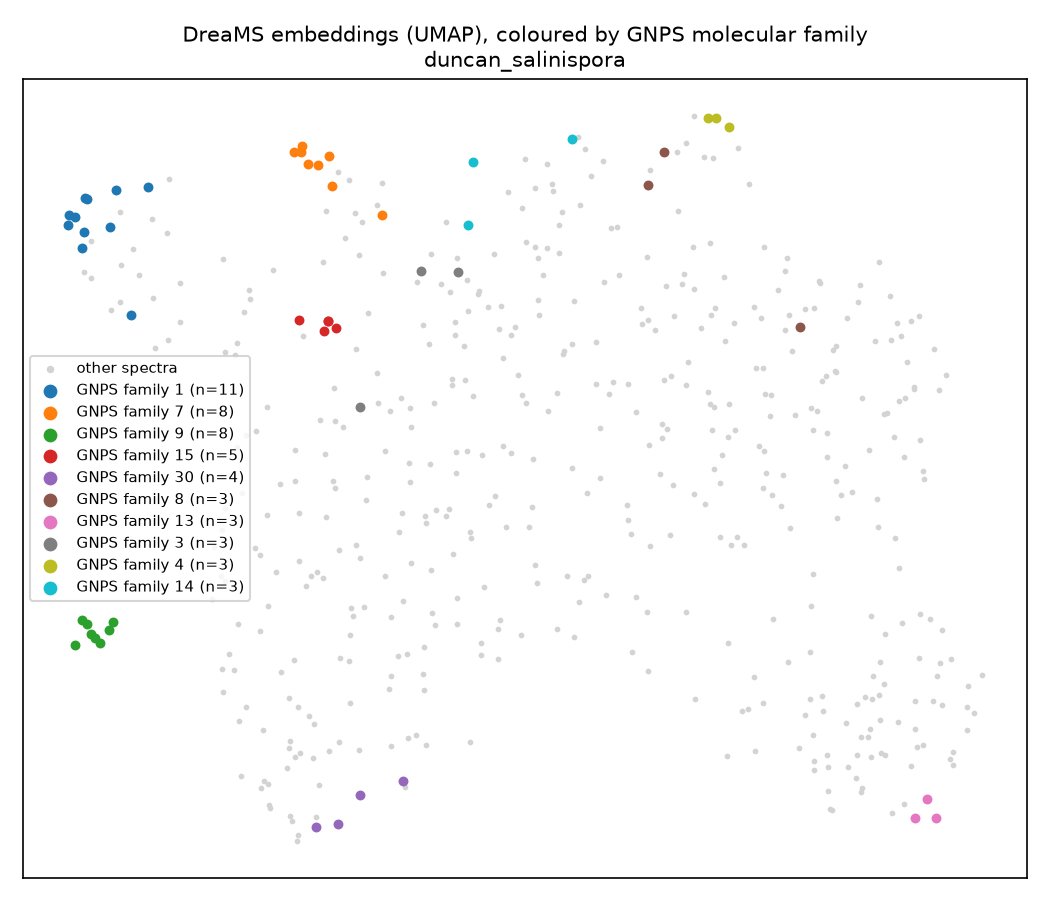

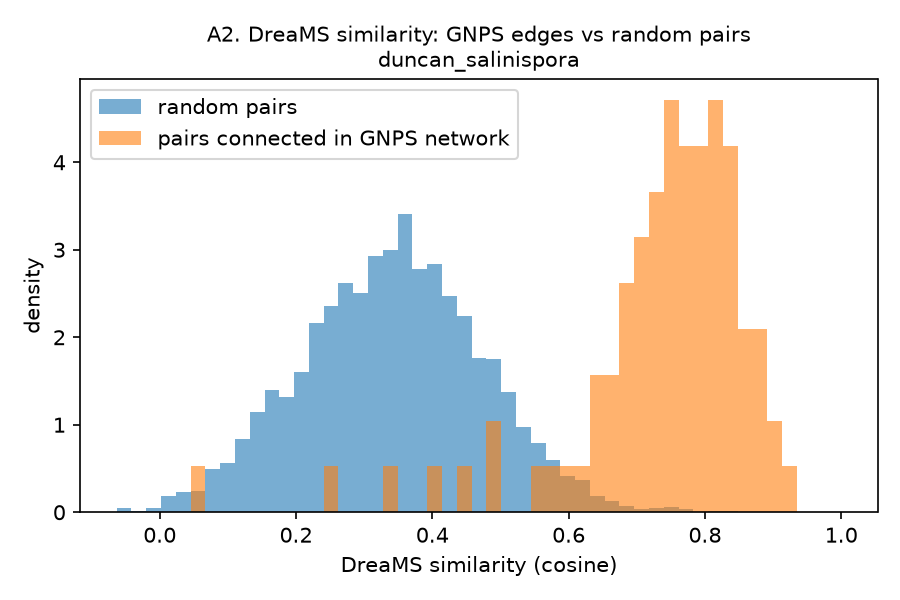

### `crusemann_salstrep` (protocol)

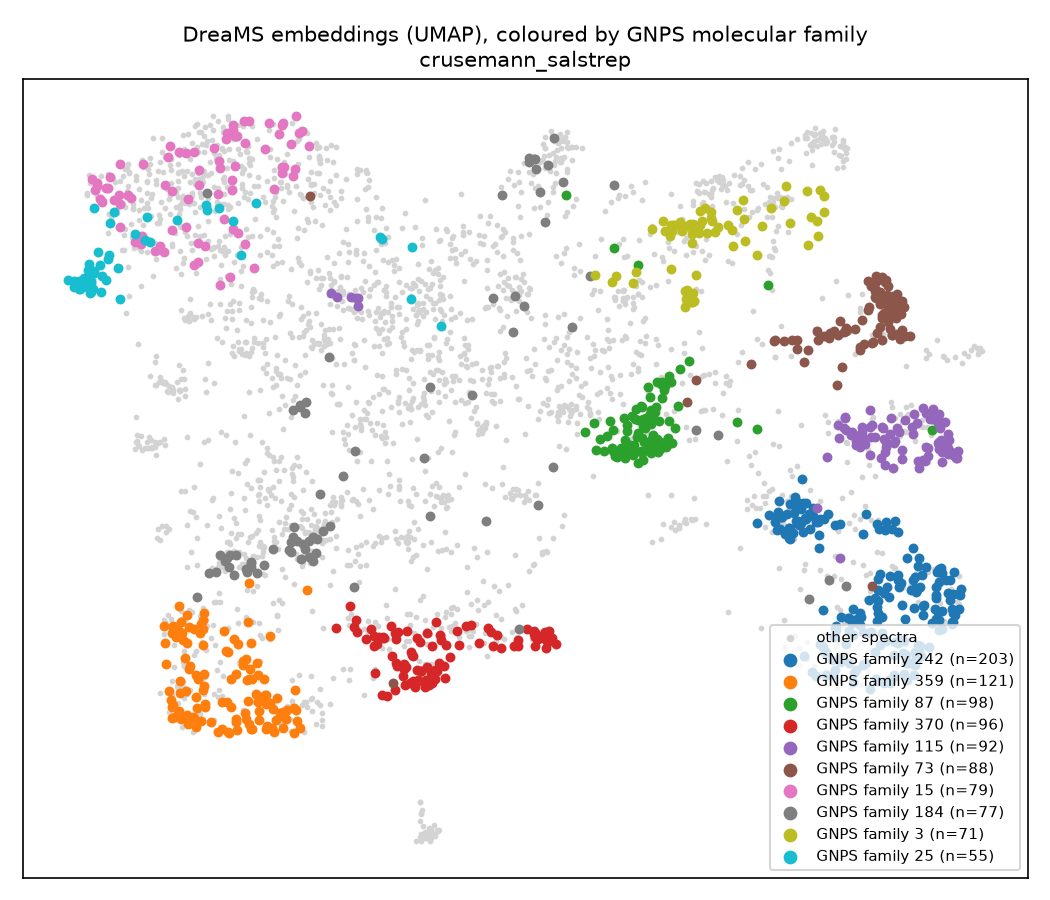

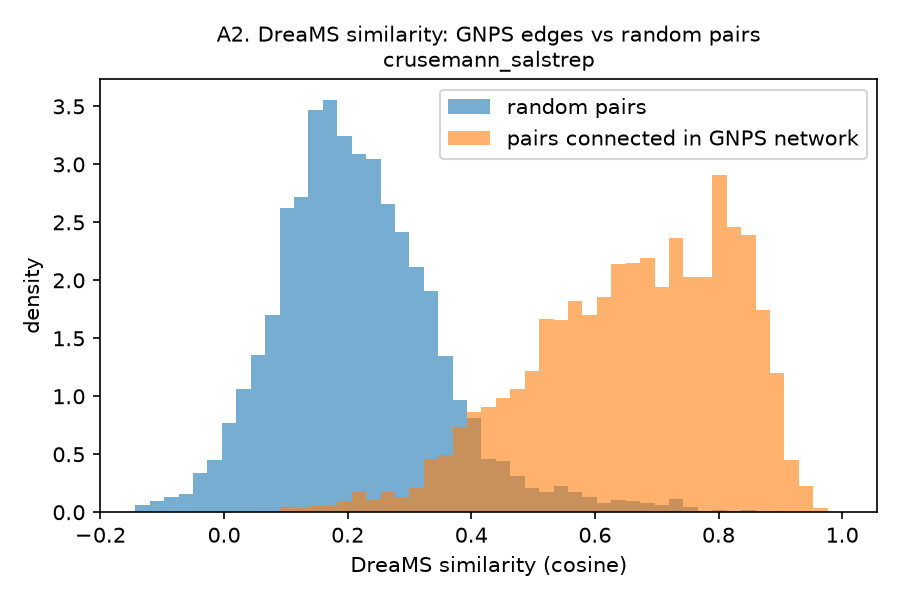

### `chevrette_insect` (protocol)

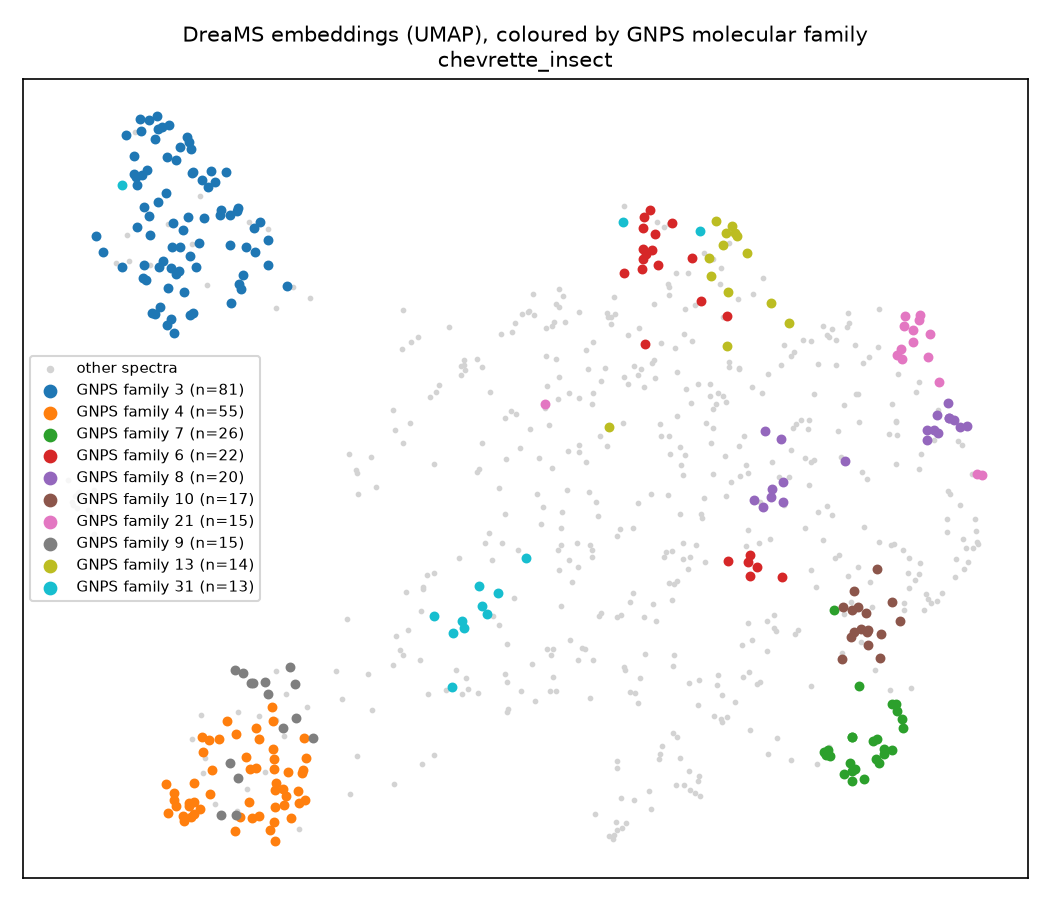

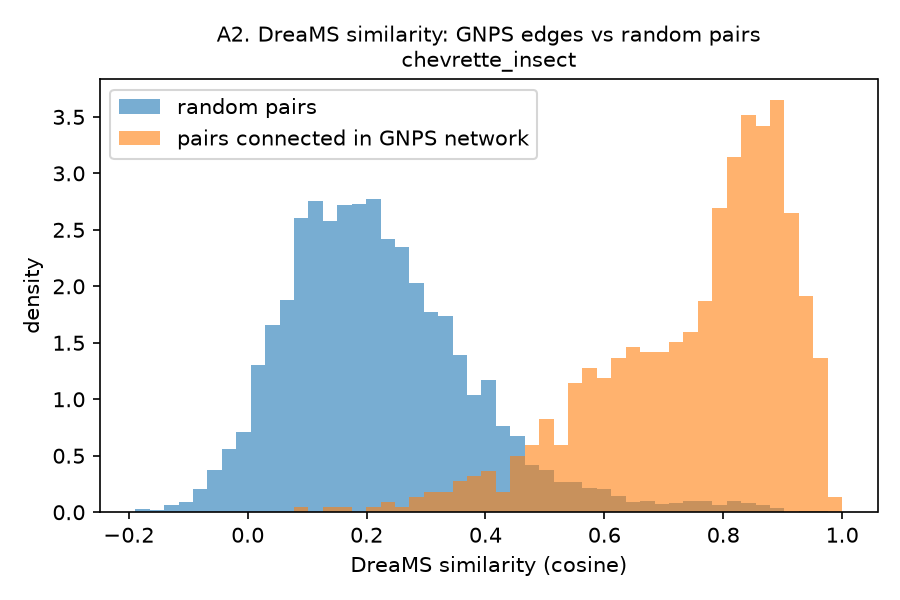

### `dorrestein_salbus` (protocol)

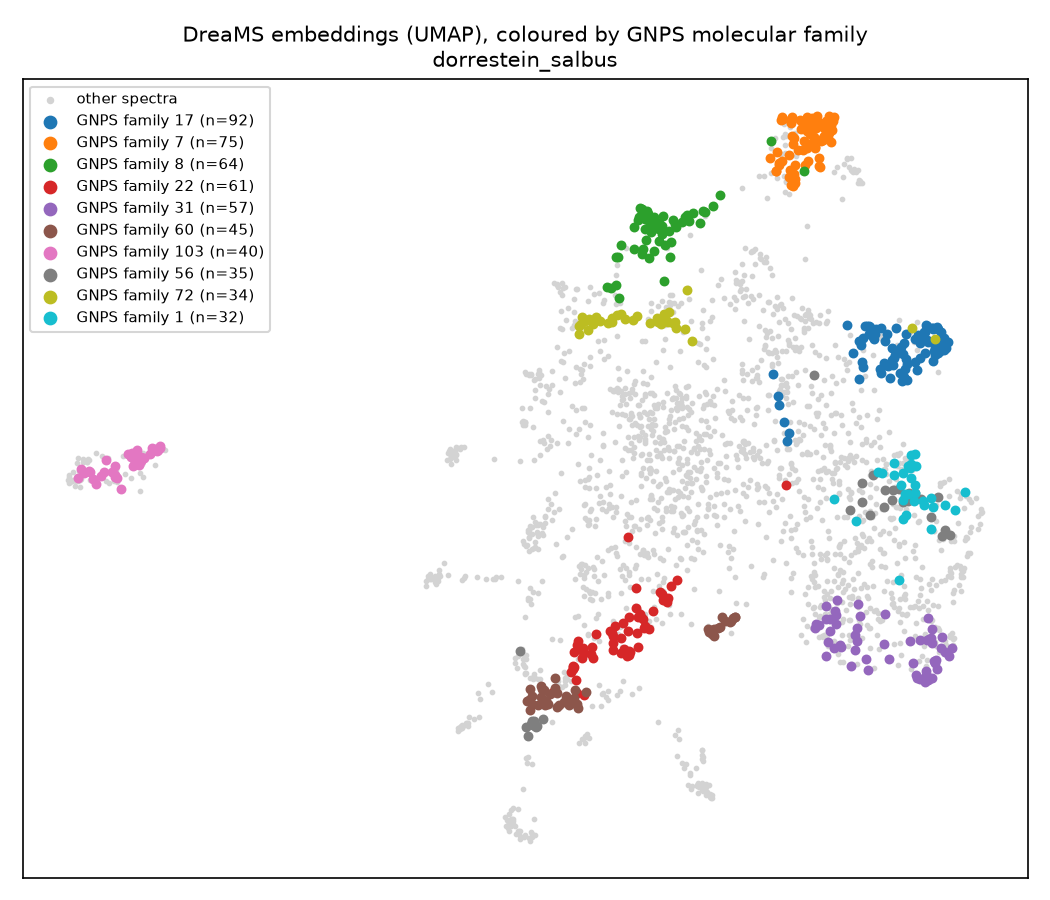

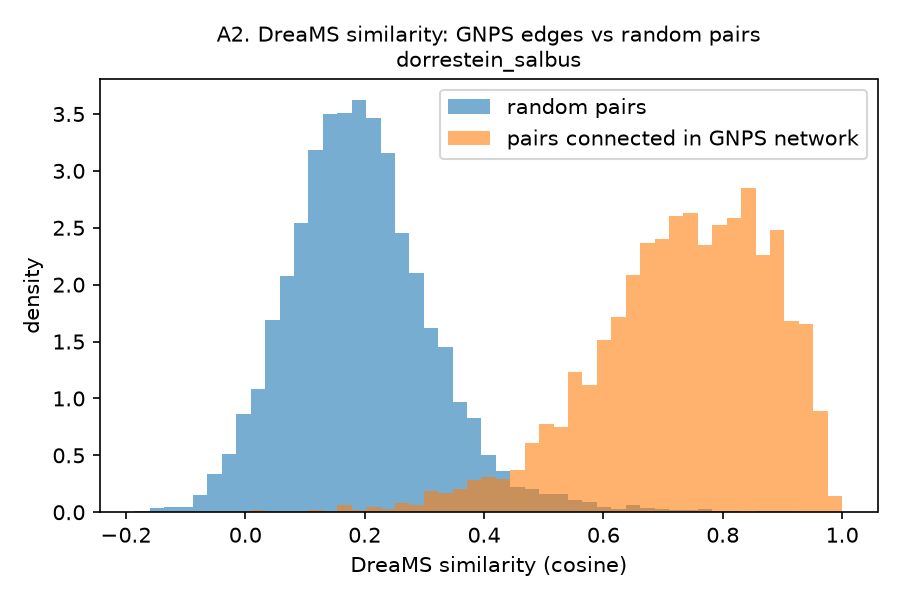

### `tahlan_streptomyces` (protocol)

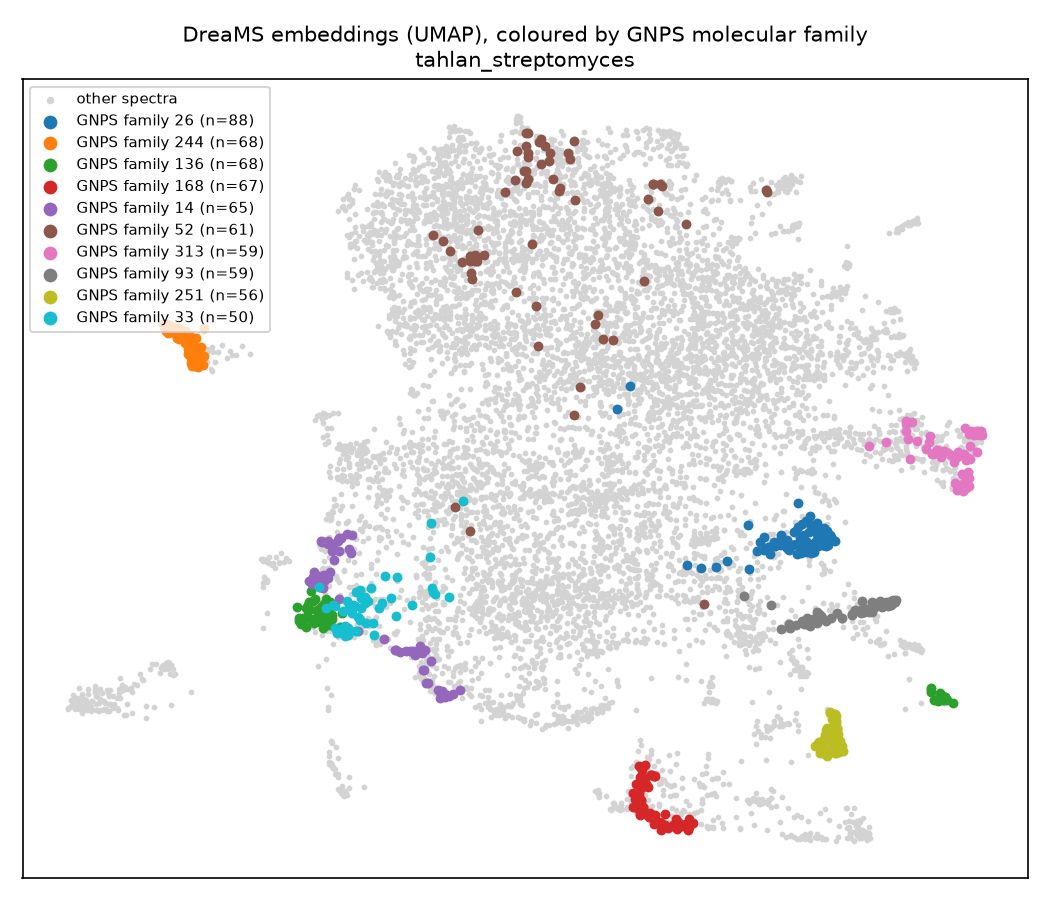

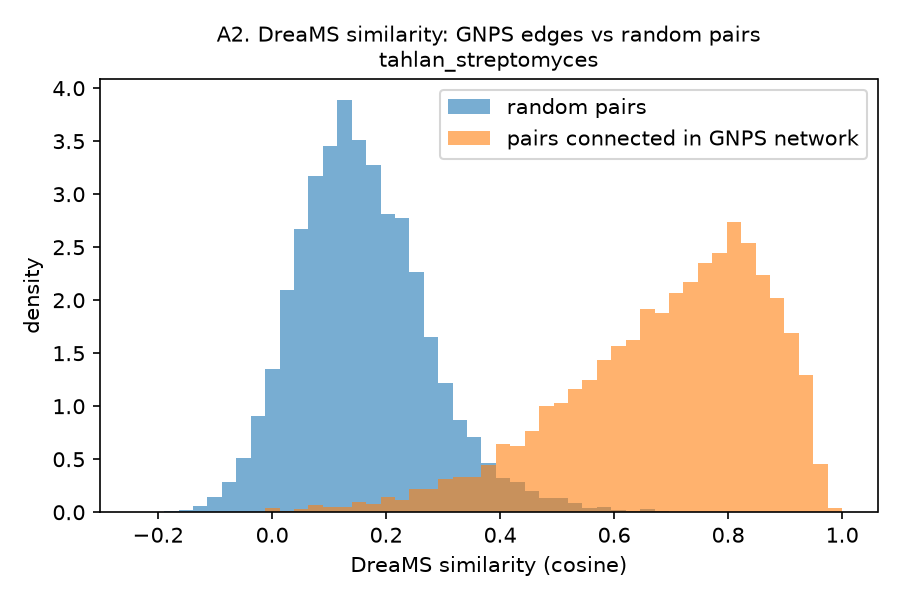

In [6]:
for run in RUNS:
    folder = EXPERIMENT_DIR / "runs" / run / "results"
    if (folder / "exp_a_umap.png").exists():
        display(Markdown(f"### `{run}` (protocol)"))
        display(Image(folder / "exp_a_umap.png", width=560))
        display(Image(folder / "exp_a_similarity_hist.png", width=460))

In [7]:
# DreaMS links that GNPS did not make (first rows). Look at the delta m/z
# (for example +14 = CH2, +16 = O) and at the library names.
for run in RUNS:
    path = EXPERIMENT_DIR / "runs" / run / "results" / "exp_a_new_links.parquet"
    if path.exists():
        display(Markdown(f"**New links: `{run}`**"))
        display(pd.read_parquet(path).head(10))

**New links: `duncan_salinispora`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,159,178,0.879,211.144,211.144,0.0,None,"NCGC00380904-01!1-(3,4-dihydroxy-5-methoxyphenyl)-7-(3,4-dihydroxyphenyl)hep...",involves a GNPS singleton
1,159,196,0.863,211.144,211.144,0.0,None,None,involves a GNPS singleton
2,87,88,0.851,157.084,157.084,0.0,None,Spectral Match to Sebuthylazine from NIST14,involves a GNPS singleton
3,192,196,0.847,211.144,211.144,0.0,HMDB:HMDB00403-614 2-Hydroxyadenine,None,involves a GNPS singleton
4,144,149,0.842,211.144,211.144,0.0,None,None,involves a GNPS singleton
5,178,196,0.840,211.144,211.144,0.0,"NCGC00380904-01!1-(3,4-dihydroxy-5-methoxyphenyl)-7-(3,4-dihydroxyphenyl)hep...",None,involves a GNPS singleton
6,178,192,0.833,211.144,211.144,0.0,"NCGC00380904-01!1-(3,4-dihydroxy-5-methoxyphenyl)-7-(3,4-dihydroxyphenyl)hep...",HMDB:HMDB00403-614 2-Hydroxyadenine,involves a GNPS singleton
7,212,216,0.832,213.149,213.149,0.0,"NCGC00380362-01!1,7-bis(3,4-dihydroxyphenyl)-6-hydroxyheptan-3-one",MLS001148114-01!147-24-0,involves a GNPS singleton
8,145,173,0.829,211.144,211.144,0.0,None,MLS002695961-01!104015-29-4,involves a GNPS singleton
9,136,143,0.828,211.144,211.144,0.0,None,None,involves a GNPS singleton


**New links: `crusemann_salstrep`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,70922,71572,0.945,634.875,634.875,0.000,None,None,involves a GNPS singleton
1,71307,71527,0.942,634.875,634.876,0.001,None,None,involves a GNPS singleton
2,71348,71527,0.940,634.875,634.876,0.001,None,None,involves a GNPS singleton
3,71527,71572,0.935,634.876,634.875,-0.001,None,None,involves a GNPS singleton
4,60635,61001,0.934,566.887,566.888,0.001,None,None,involves a GNPS singleton
5,70922,71310,0.931,634.875,634.875,0.000,None,None,involves a GNPS singleton
6,60641,61001,0.931,566.887,566.888,0.001,None,None,involves a GNPS singleton
7,61001,71649,0.930,566.888,634.876,67.988,None,None,involves a GNPS singleton
8,61001,61745,0.929,566.888,566.891,0.003,None,None,involves a GNPS singleton
9,70922,71527,0.928,634.875,634.876,0.001,None,None,involves a GNPS singleton


**New links: `chevrette_insect`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,1804,1827,0.935,953.741,953.740,-0.001,None,None,involves a GNPS singleton
1,1805,1827,0.927,953.739,953.740,0.001,None,None,involves a GNPS singleton
2,1772,1827,0.926,953.741,953.740,-0.001,None,None,involves a GNPS singleton
3,1772,2024,0.923,953.741,953.743,0.002,None,None,involves a GNPS singleton
4,1186,1248,0.910,697.328,725.346,28.018,None,None,involves a GNPS singleton
5,2039,2381,0.907,953.742,953.744,0.002,None,None,involves a GNPS singleton
6,1745,1767,0.905,953.740,953.743,0.003,None,None,involves a GNPS singleton
7,1758,1781,0.900,953.740,953.740,0.000,None,None,involves a GNPS singleton
8,1756,1772,0.899,953.740,953.741,0.001,None,None,involves a GNPS singleton
9,1772,1869,0.890,953.741,953.744,0.003,None,None,involves a GNPS singleton


**New links: `dorrestein_salbus`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,1162,1164,0.934,287.170,287.200,0.030,None,None,involves a GNPS singleton
1,1220,1221,0.902,293.680,293.690,0.010,None,None,involves a GNPS singleton
2,2965,3486,0.899,519.380,592.430,73.050,None,None,involves a GNPS singleton
3,3111,3497,0.889,539.890,594.670,54.780,None,None,involves a GNPS singleton
4,4072,4148,0.883,678.468,692.481,14.013,None,None,involves a GNPS singleton
5,4461,4489,0.879,821.578,847.590,26.012,None,None,involves a GNPS singleton
6,3429,3736,0.879,586.920,635.190,48.270,None,None,involves a GNPS singleton
7,1750,1753,0.878,347.090,347.100,0.010,None,None,involves a GNPS singleton
8,4470,4489,0.877,831.593,847.590,15.997,None,None,involves a GNPS singleton
9,3051,3429,0.876,529.130,586.920,57.790,None,None,involves a GNPS singleton


**New links: `tahlan_streptomyces`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,24573,24785,0.942,931.700,947.691,15.991,None,None,involves a GNPS singleton
1,23387,23391,0.941,856.441,857.425,0.984,None,None,involves a GNPS singleton
2,21886,23391,0.940,727.398,857.425,130.027,None,None,involves a GNPS singleton
3,19178,23788,0.933,599.503,896.771,297.268,"1,2-Dilinoleoylglycerol",None,involves a GNPS singleton
4,23234,23391,0.932,839.415,857.425,18.010,None,None,involves a GNPS singleton
5,4647,4655,0.930,261.124,261.123,-0.001,"NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...","NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...",involves a GNPS singleton
6,4655,4660,0.924,261.123,261.123,0.000,"NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...","NCGC00384639-01_C14H16N2O3_Pyrrolo[1,2-a]pyrazine-1,4-dione, hexahydro-3-[(4...",involves a GNPS singleton
7,20094,23391,0.924,643.330,857.425,214.095,None,None,involves a GNPS singleton
8,14567,23612,0.923,439.292,877.576,438.284,None,None,involves a GNPS singleton
9,24785,24882,0.923,947.691,961.672,13.981,None,None,involves a GNPS singleton


## 4. Experiment B: chemical structures

**Which annotations count** (`annotations.py`): the SMILES must be readable (largest fragment, neutralised); the hit must be an exact-mass hit (query and library precursor within 0.05 Da), which removes analog-search hits (the Duncan job ran with analog search: 1,134 of its 1,154 hits are analogs, i.e. other molecules); MQScore >= 0.7 and >= 6 shared peaks; the InChI, when given, must agree with the SMILES; for [M+H]+ hits the library precursor must agree with the structure's mass; and only one spectrum per molecule is kept ([M+H]+ first), so every pair is a pair of independent compounds.

For every pair, the structural similarity of the two compounds (Tanimoto on Morgan fingerprints; also MHFP, Daniel Probst's MinHash fingerprint) is compared with DreaMS, MS2DeepScore, modified cosine (same fragment tolerance as the GNPS job) and binned spectrum cosine.

- **B1.** Spearman correlation over all pairs. The difference between DreaMS and the other methods gets a 95% interval from resampling molecules.
- **B2.** Analog search: for each compound, take the most similar spectrum (always another molecule) and check the Tanimoto of the two molecules.
- A dataset counts for conclusions only with at least 100 independent compounds (`B used for conclusions`). After the checks, only the Tahlan job has that many.

done: exp_b_structures.py --run duncan_salinispora --variant protocol (4 s)


done: exp_b_structures.py --run crusemann_salstrep --variant protocol (3 s)


skipped: exp_b_structures.py --run crusemann_streptomyces --variant protocol: crusemann_streptomyces has no spectra for the 'protocol' variant (none pass the rules, or prepare_data.py has not run).



done: exp_b_structures.py --run chevrette_insect --variant protocol (7 s)


done: exp_b_structures.py --run dorrestein_salbus --variant protocol (3 s)


done: exp_b_structures.py --run tahlan_streptomyces --variant protocol (12 s)


... (3 outputs left out)

done: exp_b_structures.py --run chevrette_insect --variant all_kept (6 s)


done: exp_b_structures.py --run dorrestein_salbus --variant all_kept (3 s)


done: exp_b_structures.py --run tahlan_streptomyces --variant all_kept (12 s)


,duncan_salinispora,crusemann_salstrep,chevrette_insect,dorrestein_salbus,tahlan_streptomyces
metric,,,,,
annotation check: library hits with a SMILES,135,55,36,54,442
annotation check: SMILES read by RDKit,130,21,29,32,420
annotation check: exact-mass hits (|query - library precursor| <= 0.05 Da),2,8,28,32,419
annotation check: MQScore >= 0.7 and >= 6 shared peaks,1,2,28,17,214
annotation check: InChI agrees with SMILES (when an InChI is given),1,2,28,17,214
annotation check: [M+H]+ hits: library precursor agrees with the structure (<= 0.05 Da),1,2,26,16,211
annotation check: independent compounds (one spectrum per molecule),1,2,21,16,176
annotated spectra used,1,2,21,16,176
note,too few annotated spectra for this test,too few annotated spectra for this test,,too few annotated spectra for this test,


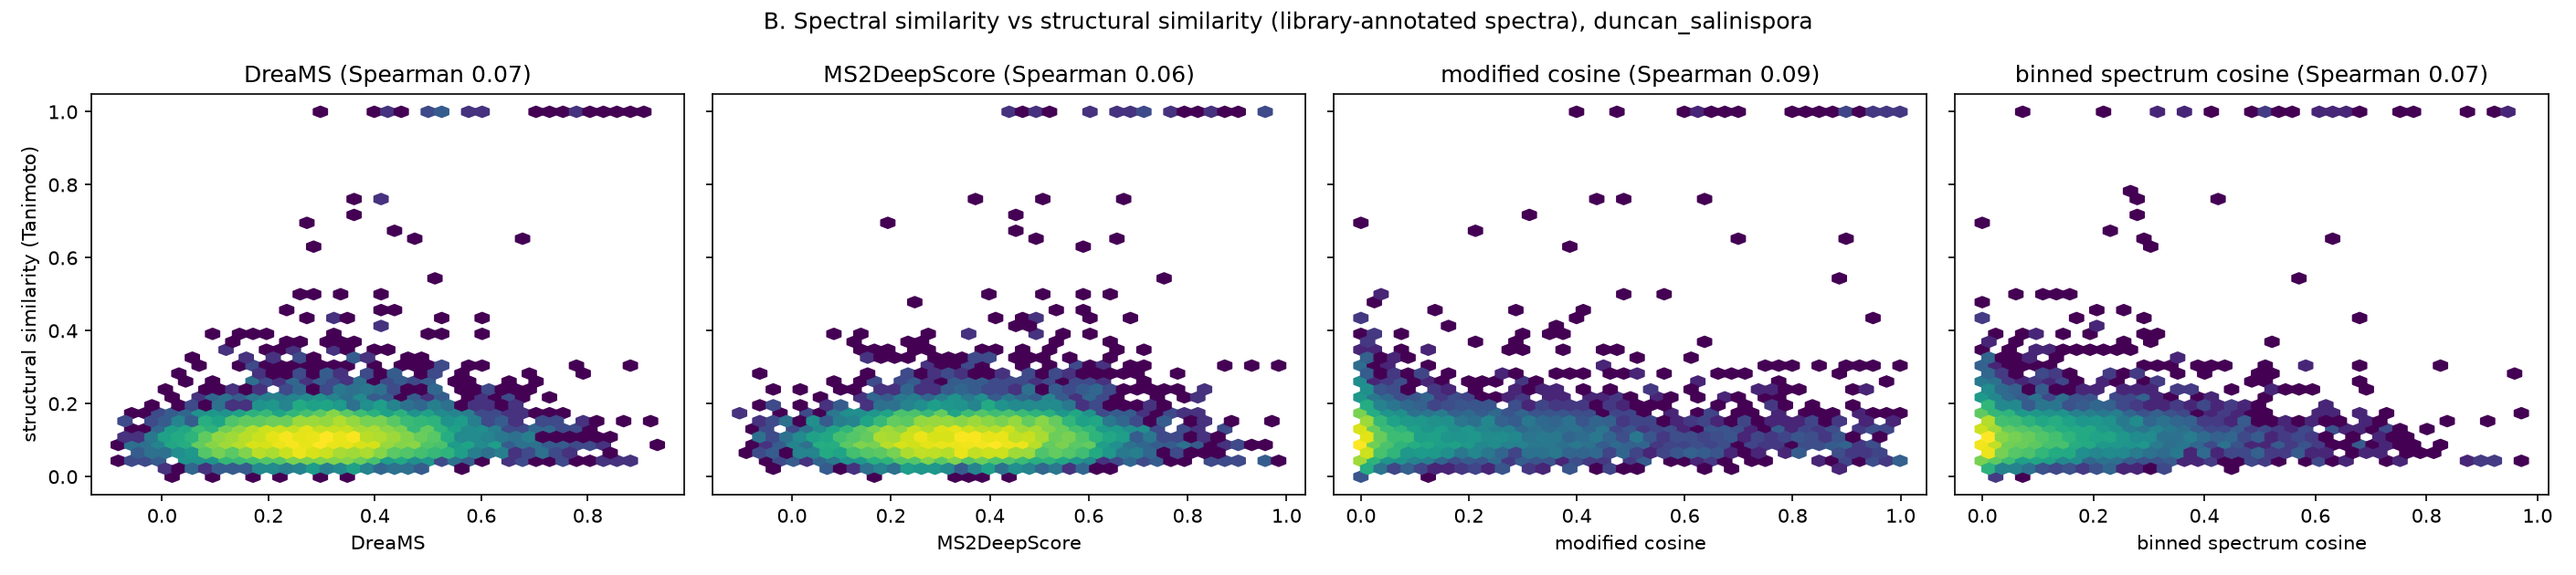

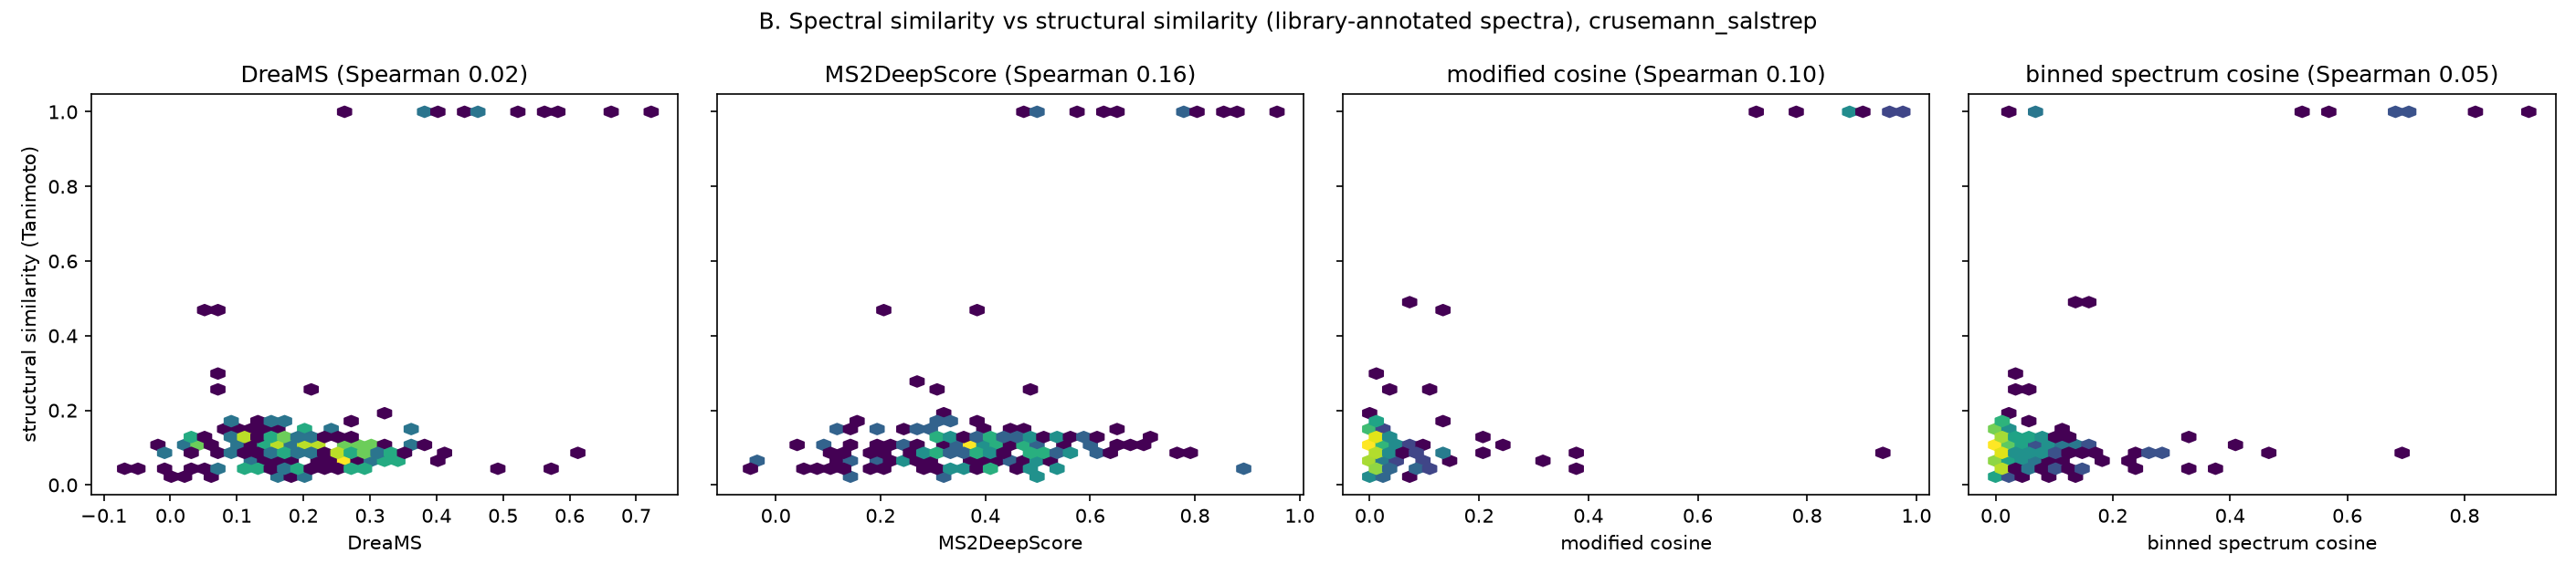

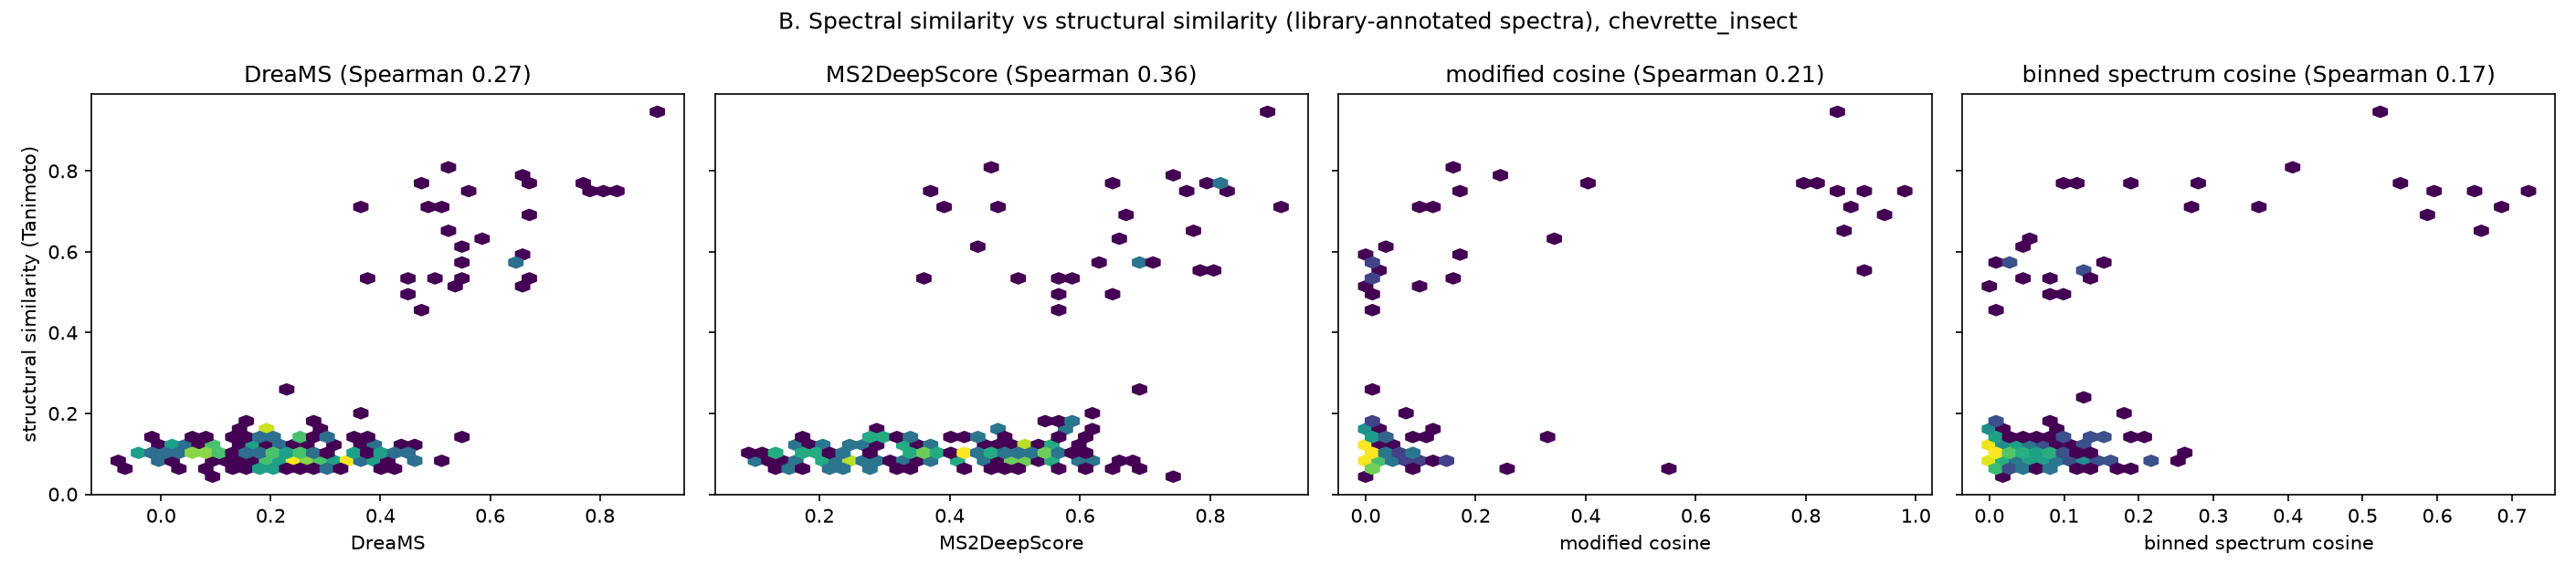

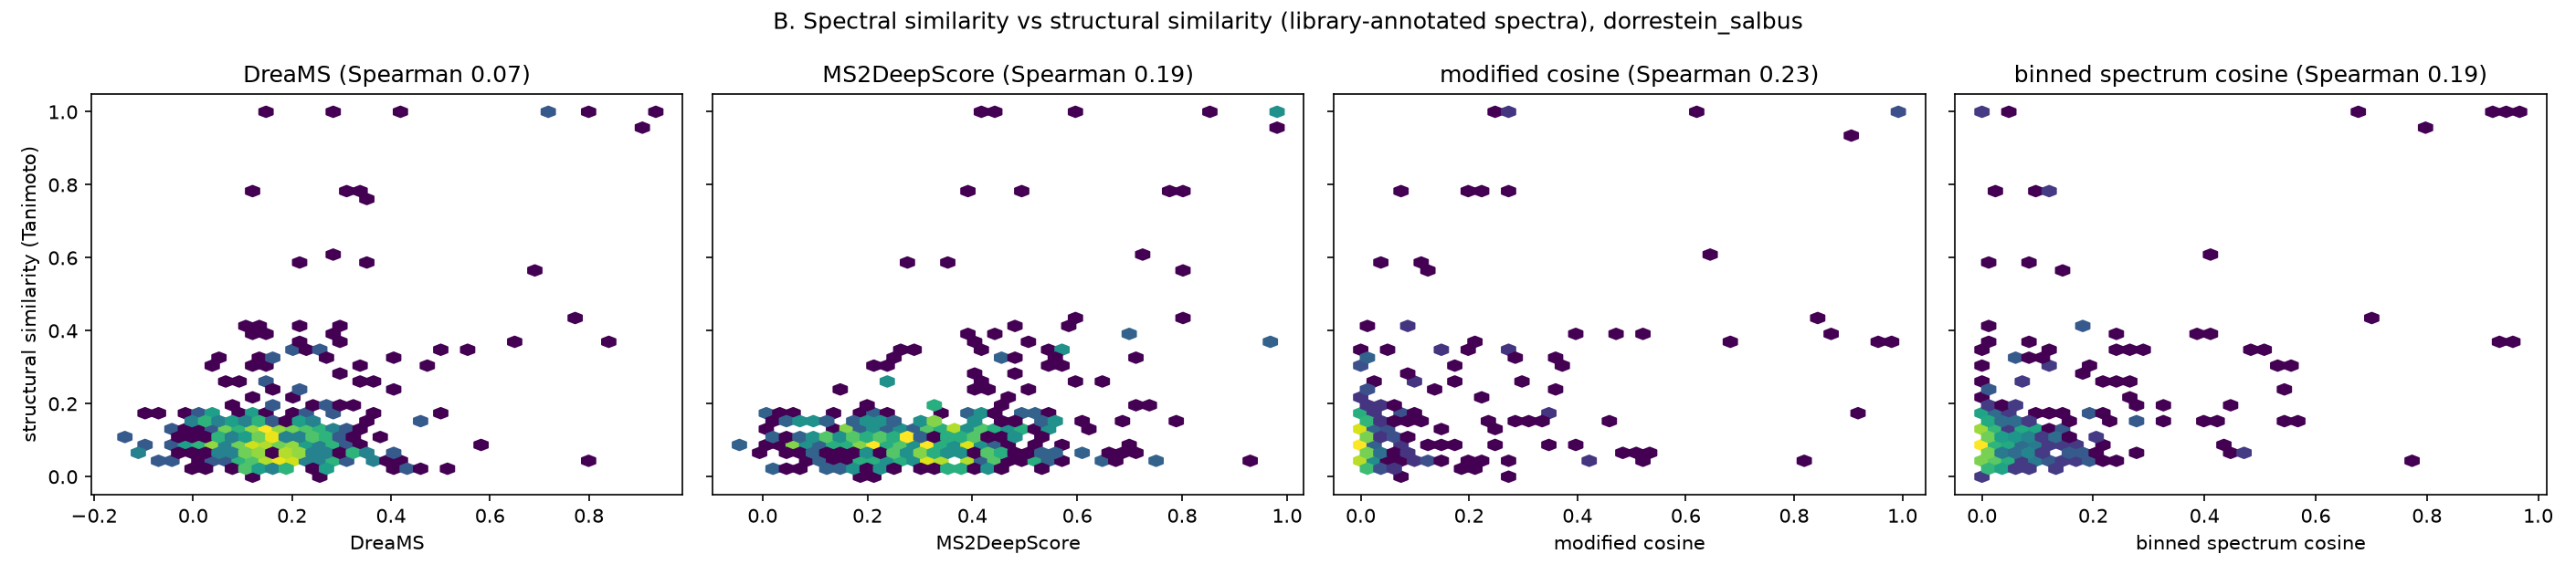

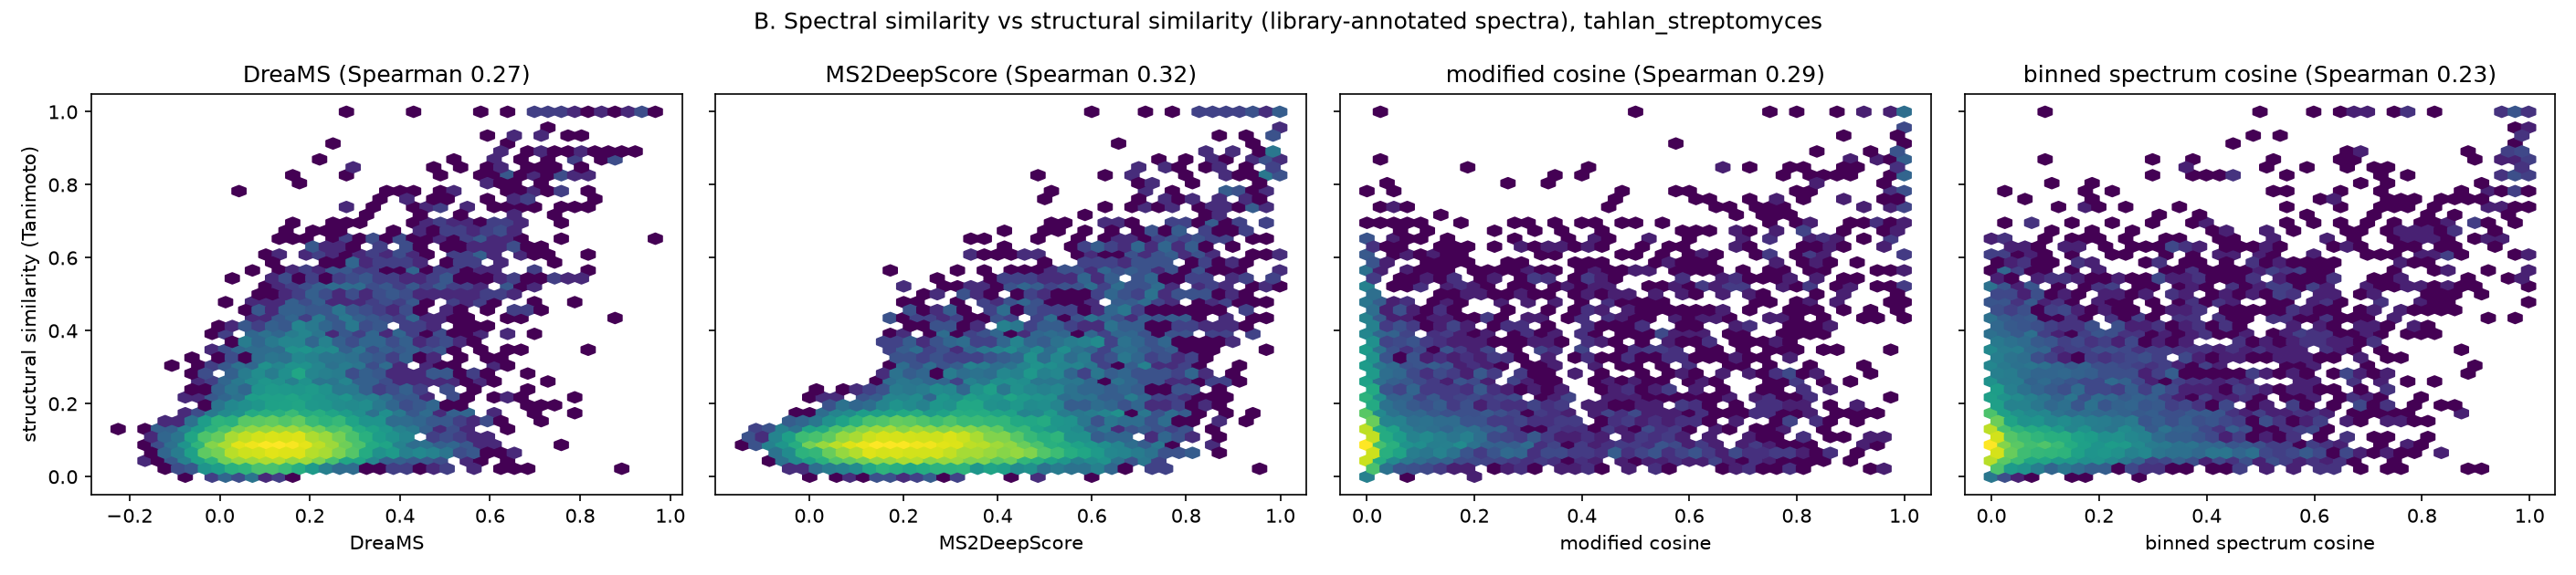

In [8]:
for variant in VARIANTS:
    for run in RUNS:
        step("exp_b_structures.py", "--run", run, "--variant", variant, allow_fail=True)

display(side_by_side("exp_b_summary"))
for run in RUNS:
    figure = EXPERIMENT_DIR / "runs" / run / "results" / "exp_b_structure.png"
    if figure.exists():
        display(Image(figure, width=1000))

## 5. Experiment C (prototype): a small layer trained across labs

A linear layer on top of the frozen DreaMS embeddings is trained so that the cosine of two compounds follows the Tanimoto of their molecules (the training target of MS2DeepScore), on the validated annotations. The design was fixed before looking at test results:

- 5 random splits by molecule (test 25%, validation 15% of the rest).
- Three client partitions of the training compounds: one client per lab (natural), IID (5 equal clients) and Dirichlet(0.5) over 8 chemical classes (label skew).
- Same model, learning rate and budget for all methods; the step or round is chosen on the validation compounds: pre-trained DreaMS, local, centralised, FedAvg, FedProx (mu = 0.01) and SplitFedV2-like.
- Means with 95% t-intervals over splits, and paired differences against pre-trained DreaMS and against centralised training. An advantage is claimed only when the paired interval excludes 0.

In [9]:
for variant in VARIANTS:
    step("exp_c_federated_adapter.py", "--variant", variant)
display(Markdown((EXPERIMENT_DIR / "federated_prototype" / "RESULTS_federated_prototype.md").read_text(encoding="utf-8")))

done: exp_c_federated_adapter.py --variant protocol (328 s)


done: exp_c_federated_adapter.py --variant all_kept (326 s)


# Experiment C: a layer on frozen DreaMS, trained centrally and across clients

Generated by `scripts/exp_c_federated_adapter.py`, variant `protocol`. 5 random splits by molecule (test 25%, validation 15% of the rest). The design is described at the top of the script; it was fixed before looking at test results. Values are means over splits with a 95% t-interval. *Paired* columns compare methods on the same split. **An advantage is claimed only when the paired interval excludes 0.**

## Compounds

Library-annotated compounds that pass the checks of `annotations.py`, per lab:

| lab | compounds |
|---|---|
| chevrette_insect | 21 |
| crusemann_salstrep | 2 |
| dorrestein_salbus | 16 |
| duncan_salinispora | 1 |
| tahlan_streptomyces | 176 |

Clients per partition (compounds per client shown for split 0):

| partition | clients | example_split_0 | validation | test |
|---|---|---|---|---|
| dirichlet | 5 | 12, 32, 41, 12, 42 | 25 | 52 |
| iid | 5 | 28, 28, 28, 28, 27 | 25 | 52 |
| labs | 3 | 12, 10, 114 | 25 | 52 |

## Spearman with Tanimoto

| partition | method | Spearman with Tanimoto (mean, 95% CI over splits) | minus pre-trained (paired) | minus centralised (paired) |
|---|---|---|---|---|
| dirichlet | FedAvg | +0.281 [+0.190, +0.371] | +0.026 [-0.019, +0.071] | -0.027 [-0.114, +0.060] |
| dirichlet | FedProx (mu=0.01) | +0.276 [+0.212, +0.340] | +0.021 [-0.003, +0.046] | -0.032 [-0.122, +0.058] |
| dirichlet | SplitFedV2-like (clients one after the other) | +0.270 [+0.194, +0.346] | +0.015 [-0.023, +0.053] | -0.038 [-0.144, +0.068] |
| dirichlet | centralised (all compounds in one place) | +0.308 [+0.241, +0.375] | +0.053 [-0.039, +0.145] |  |
| dirichlet | local (mean over clients) | +0.230 [+0.174, +0.285] | -0.025 [-0.045, -0.005] | -0.078 [-0.153, -0.004] |
| dirichlet | pre-trained DreaMS (no training) | +0.255 [+0.187, +0.322] |  |  |
| iid | FedAvg | +0.301 [+0.228, +0.375] | +0.047 [-0.032, +0.126] | -0.007 [-0.039, +0.026] |
| iid | FedProx (mu=0.01) | +0.293 [+0.216, +0.370] | +0.038 [-0.050, +0.126] | -0.015 [-0.052, +0.021] |
| iid | SplitFedV2-like (clients one after the other) | +0.281 [+0.220, +0.341] | +0.026 [-0.040, +0.092] | -0.027 [-0.061, +0.007] |
| iid | centralised (all compounds in one place) | +0.308 [+0.241, +0.375] | +0.053 [-0.039, +0.146] |  |
| iid | local (mean over clients) | +0.236 [+0.186, +0.286] | -0.019 [-0.074, +0.036] | -0.072 [-0.137, -0.008] |
| iid | pre-trained DreaMS (no training) | +0.255 [+0.187, +0.322] |  |  |
| labs | FedAvg | +0.322 [+0.241, +0.402] | +0.067 [-0.012, +0.147] | +0.006 [-0.030, +0.042] |
| labs | FedProx (mu=0.01) | +0.319 [+0.245, +0.392] | +0.064 [-0.027, +0.155] | +0.003 [-0.025, +0.031] |
| labs | SplitFedV2-like (clients one after the other) | +0.292 [+0.219, +0.366] | +0.038 [-0.032, +0.108] | -0.023 [-0.075, +0.029] |
| labs | centralised (all compounds in one place) | +0.316 [+0.255, +0.377] | +0.061 [-0.027, +0.149] |  |
| labs | local (mean over clients) | +0.254 [+0.197, +0.311] | -0.001 [-0.031, +0.030] | -0.062 [-0.121, -0.002] |
| labs | pre-trained DreaMS (no training) | +0.255 [+0.187, +0.322] |  |  |

## analog search top-1 Tanimoto

| partition | method | analog search top-1 Tanimoto (mean, 95% CI over splits) | minus pre-trained (paired) | minus centralised (paired) |
|---|---|---|---|---|
| dirichlet | FedAvg | +0.365 [+0.342, +0.389] | +0.004 [-0.009, +0.017] | -0.005 [-0.042, +0.031] |
| dirichlet | FedProx (mu=0.01) | +0.358 [+0.323, +0.393] | -0.004 [-0.016, +0.008] | -0.013 [-0.042, +0.017] |
| dirichlet | SplitFedV2-like (clients one after the other) | +0.342 [+0.301, +0.383] | -0.020 [-0.035, -0.004] | -0.029 [-0.060, +0.002] |
| dirichlet | centralised (all compounds in one place) | +0.371 [+0.317, +0.424] | +0.009 [-0.016, +0.034] |  |
| dirichlet | local (mean over clients) | +0.336 [+0.305, +0.367] | -0.025 [-0.033, -0.018] | -0.034 [-0.066, -0.003] |
| dirichlet | pre-trained DreaMS (no training) | +0.361 [+0.328, +0.395] |  |  |
| iid | FedAvg | +0.370 [+0.323, +0.417] | +0.009 [-0.017, +0.034] | -0.000 [-0.044, +0.043] |
| iid | FedProx (mu=0.01) | +0.374 [+0.327, +0.421] | +0.012 [-0.016, +0.041] | +0.003 [-0.042, +0.049] |
| iid | SplitFedV2-like (clients one after the other) | +0.364 [+0.321, +0.407] | +0.002 [-0.016, +0.021] | -0.007 [-0.038, +0.025] |
| iid | centralised (all compounds in one place) | +0.371 [+0.317, +0.424] | +0.009 [-0.016, +0.034] |  |
| iid | local (mean over clients) | +0.348 [+0.314, +0.382] | -0.013 [-0.026, -0.000] | -0.022 [-0.057, +0.013] |
| iid | pre-trained DreaMS (no training) | +0.361 [+0.328, +0.395] |  |  |
| labs | FedAvg | +0.374 [+0.320, +0.429] | +0.013 [-0.011, +0.037] | +0.001 [-0.017, +0.019] |
| labs | FedProx (mu=0.01) | +0.370 [+0.333, +0.407] | +0.009 [-0.002, +0.019] | -0.004 [-0.034, +0.027] |
| labs | SplitFedV2-like (clients one after the other) | +0.353 [+0.301, +0.405] | -0.008 [-0.034, +0.018] | -0.021 [-0.058, +0.017] |
| labs | centralised (all compounds in one place) | +0.374 [+0.317, +0.430] | +0.012 [-0.015, +0.039] |  |
| labs | local (mean over clients) | +0.341 [+0.298, +0.383] | -0.021 [-0.041, -0.000] | -0.033 [-0.065, -0.001] |
| labs | pre-trained DreaMS (no training) | +0.361 [+0.328, +0.395] |  |  |

## Limitations

- Few compounds: most come from one lab (Tahlan), so the natural partition has few, very unequal clients.
- Library annotations are putative even after the checks; the target is noisy.
- The DreaMS embedding model was fine-tuned on public library spectra; some test molecules may be among them, which favours the pre-trained model.
- Simulated on one machine, without communication costs or privacy measures.


## 6. Experiment D: how different are the labs?

A federated study needs a measured heterogeneity. Can a logistic regression tell two labs apart from their embeddings? Balanced accuracy 0.5 = the labs look the same, 1.0 = fully separated. Labs differ in chemistry and in measurement at the same time; the test on molecules that both labs measured holds the chemistry fixed.

In [10]:
step("exp_d_lab_shift.py")
display(Markdown((EXPERIMENT_DIR / "lab_shift" / "RESULTS_lab_shift_protocol.md").read_text(encoding="utf-8")))

done: exp_d_lab_shift.py  (8 s)


# Experiment D: how different are the labs?

Generated by `scripts/exp_d_lab_shift.py`, variant `protocol`. Logistic regression, 5-fold cross-validation, the same number of spectra from both labs (at most 1500). Balanced accuracy 0.5 = the two labs look the same, 1.0 = fully separated. *Shared molecules* repeats the test on library-annotated spectra of molecules measured in both labs (only when each lab has at least 10 of them), so that chemistry is held fixed.

| lab A | lab B | representation | all spectra: balanced accuracy | spectra per lab | shared molecules |
|---|---|---|---|---|---|
| duncan_salinispora | crusemann_salstrep | DreaMS | 0.975 | 528 | 0 |
| duncan_salinispora | crusemann_salstrep | binned spectrum | 0.98 | 528 | 0 |
| duncan_salinispora | crusemann_salstrep | MS2DeepScore | 0.928 | 528 | 0 |
| duncan_salinispora | chevrette_insect | DreaMS | 0.966 | 528 | 0 |
| duncan_salinispora | chevrette_insect | binned spectrum | 0.987 | 528 | 0 |
| duncan_salinispora | chevrette_insect | MS2DeepScore | 0.911 | 528 | 0 |
| duncan_salinispora | dorrestein_salbus | DreaMS | 0.974 | 528 | 0 |
| duncan_salinispora | dorrestein_salbus | binned spectrum | 0.968 | 528 | 0 |
| duncan_salinispora | dorrestein_salbus | MS2DeepScore | 0.894 | 528 | 0 |
| duncan_salinispora | tahlan_streptomyces | DreaMS | 0.978 | 528 | 0 |
| duncan_salinispora | tahlan_streptomyces | binned spectrum | 0.978 | 528 | 0 |
| duncan_salinispora | tahlan_streptomyces | MS2DeepScore | 0.903 | 528 | 0 |
| crusemann_salstrep | chevrette_insect | DreaMS | 0.913 | 785 | 0 |
| crusemann_salstrep | chevrette_insect | binned spectrum | 0.931 | 785 | 0 |
| crusemann_salstrep | chevrette_insect | MS2DeepScore | 0.851 | 785 | 0 |
| crusemann_salstrep | dorrestein_salbus | DreaMS | 0.913 | 1500 | 1 |
| crusemann_salstrep | dorrestein_salbus | binned spectrum | 0.924 | 1500 | 1 |
| crusemann_salstrep | dorrestein_salbus | MS2DeepScore | 0.852 | 1500 | 1 |
| crusemann_salstrep | tahlan_streptomyces | DreaMS | 0.919 | 1500 | 1 |
| crusemann_salstrep | tahlan_streptomyces | binned spectrum | 0.914 | 1500 | 1 |
| crusemann_salstrep | tahlan_streptomyces | MS2DeepScore | 0.824 | 1500 | 1 |
| chevrette_insect | dorrestein_salbus | DreaMS | 0.92 | 785 | 2 |
| chevrette_insect | dorrestein_salbus | binned spectrum | 0.959 | 785 | 2 |
| chevrette_insect | dorrestein_salbus | MS2DeepScore | 0.87 | 785 | 2 |
| chevrette_insect | tahlan_streptomyces | DreaMS | 0.955 | 785 | 5 |
| chevrette_insect | tahlan_streptomyces | binned spectrum | 0.976 | 785 | 5 |
| chevrette_insect | tahlan_streptomyces | MS2DeepScore | 0.889 | 785 | 5 |
| dorrestein_salbus | tahlan_streptomyces | DreaMS | 0.845 | 1500 | 7 |
| dorrestein_salbus | tahlan_streptomyces | binned spectrum | 0.865 | 1500 | 7 |
| dorrestein_salbus | tahlan_streptomyces | MS2DeepScore | 0.754 | 1500 | 7 |

Labs differ in chemistry and in measurement at the same time, so a high accuracy on all spectra alone does not show an instrument effect. Library annotations are putative.


## 7. Could DreaMS be tested for genome-metabolome linking?

NPLinker-style linking connects molecular families to gene cluster families through their presence across strains, and is judged on known BGC-spectrum links. A fair test of DreaMS for this needs many strains with genomes, known links, and spectra that DreaMS accepts.

In [11]:
step("linking_feasibility.py")
display(Markdown((EXPERIMENT_DIR / "linking_feasibility" / "RESULTS_linking_feasibility.md").read_text(encoding="utf-8")))

done: linking_feasibility.py  (15 s)


# Can DreaMS be tested for genome-metabolome linking with public data?

Generated by `scripts/linking_feasibility.py` from the GNPS jobs of the actinobacterial PoDP datasets on this laptop and `data/derived/podp_projects.csv`. *Usable* means at least 10 genomes (strain variation for correlation-based linking), at least 3 known BGC-MS2 links and at least 50% of the spectra accepted by DreaMS's own format A check. These thresholds are our choice.

| MassIVE | GNPS task | PI | genomes | known BGC-MS2 links | fragment tolerance (Da) | spectra with peaks | pass DreaMS's own check | share | usable for a linking test |
|---|---|---|---|---|---|---|---|---|---|
| MSV000078836 | 9360fa51 | Max Crüsemann | 120 | 9 | 0.5 | 6246 | 3445 | 55% | yes |
| MSV000084771 | a50dc9e2 | Leonard Kaysser, Nadine Ziemert | 11 | 9 | 0.04 | 11464 | 319 | 3% | no |
| MSV000083648 | e76dfbd2 | Neil Kelleher | 3 | 7 | 0.02 | 1323 | 175 | 13% | no |
| MSV000083835 | 8943515e | Kapil Tahlan | 4 | 6 | 0.5 | 3281 | 2444 | 74% | no |
| MSV000083835 | b5eb3498 | Kapil Tahlan | 4 | 6 | 0.02 | 12719 | 8901 | 70% | no |
| MSV000078839 | 840eadb0 | Ellis O'Neill | 39 | 5 | 0.5 | 2834 | 0 | 0% | no |
| MSV000079519 | 7e463ca8 | Pieter C. Dorrestein | 1 | 5 | 0.01 | 4707 | 2392 | 51% | no |
| MSV000079284 | c22f44b1 | Dr. Katherine Duncan | 28 | 2 | 0.3 | 25935 | 528 | 2% | no |
| MSV000082988 | 8fd1fcfa | Gilles P. van Wezel | 1 | 1 | 0.5 | 183 | 101 | 55% | no |
| MSV000083081 | 24d515f7 | Bradley Moore | 1 | 1 | 0.5 | 1080 | 0 | 0% | no |
| MSV000087784 | 78cfa392 | Gilles van Wezel | 1 | 1 | 0.02 | 285 | 224 | 79% | no |
| MSV000084723 | 927974dc | Cameron Currie & Tim Bugni | 120 | 0 | 0.02 | 1214 | 785 | 65% | no |
| MSV000084989 | 471d8f87 | Ki Hyun Kim | 1 | 0 | 0.5 | 169 | 29 | 17% | no |

## Known links of the usable dataset: can DreaMS see the molecules?

Library-annotated spectra of each linked molecule, and how many pass DreaMS's own check. Format A accepts only charge +1 and precursor m/z up to 1000, so large or doubly charged molecules are out of the DreaMS domain.

| MassIVE | known link | annotated spectra | pass DreaMS's own check | precursor m/z |
|---|---|---|---|---|
| MSV000078836 | staurosporine (BGC0000827) | 10 | 10 | 466, 467, 482, 483 |
| MSV000078836 | cyclomarin (BGC0000333) | 2 | 0 | 1026, 1036 |
| MSV000078836 | desferrioxamine (BGC0000940) | 6 | 6 | 561, 601, 623, 730, 758 |
| MSV000078836 | lomaiviticin (BGC0000241) | 3 | 0 | 670, 677, 684 |
| MSV000078836 | retimycin (BGC0001228) | 1 | 0 | 1171 |
| MSV000078836 | rifamycin S and W (BGC0000137, two links) | 3 | 2 | 656, 696, 718 |
| MSV000078836 | rosamicin (BGC0001830) | 7 | 3 | 582, 583, 598, 600 |
| MSV000078836 | arenimycin (BGC0000198) | 3 | 3 | 668, 809 |


## 8. All results in one page, and automatic checks

`scripts/report.py` writes `RESULTS.md`. `scripts/check_pipeline.py` runs unit checks, checks that every file matches its spectra, and compares the summaries with the saved reference in `tests/reference/`.

In [12]:
step("report.py", "--runs", *RUNS)
step("check_pipeline.py", show=True)

done: report.py --runs duncan_salinispora crusemann_salstrep crusemann_streptomyces chevrette_insect dorrestein_salbus tahlan_streptomyces (1 s)


ok    GNPS check accepts consistent files
ok    GNPS check catches an extra node
ok    GNPS check catches an edge to an unknown node
ok    GNPS check catches a library hit on an unknown node
ok    bootstrap interval of a constant is the constant
ok    resampling whole groups gives a wider interval
ok    annotation checks drop analog, low-score and wrong-mass hits and keep one spectrum per molecule
ok    adduct names are normalised
ok    top_peaks keeps the 100 most intense peaks in m/z order
ok    the spectra fingerprint ignores the charge line, the file md5 does not
ok    unknown charge stays unknown when written and read back
ok    DreaMS tutorial reproduction exists
ok    DreaMS tutorial was reproduced
ok    duncan_salinispora: run_info.json exists
ok    duncan_salinispora: input_report.parquet exists
ok    duncan_salinispora: provenance.json exists
ok    duncan_salinispora: provenance check passed
ok    duncan_salinispora (protocol): spectra count recorded in run_info
ok    duncan_

## 9. How to read the results

Write your own interpretation here before the meeting. Some guiding questions:
- Does our setup reproduce the DreaMS tutorial (section 0b)? If not, nothing below can be trusted yet.
- In A1, do the 95% intervals of *DreaMS minus binned cosine* and *DreaMS minus MS2DeepScore* contain 0? Is it the same in all datasets?
- In B, how many annotations survive the checks in each dataset? In the dataset that counts (Tahlan), is DreaMS better than modified cosine and MS2DeepScore, or not detectably different?
- How do the `protocol` and `all_kept` results differ, especially for Duncan?
- In C, does any trained layer beat pre-trained DreaMS (paired interval excluding 0)? Does federated training keep up with centralised training in the IID, Dirichlet and lab partitions?
- In D, are the labs different only in chemistry, or also in measurement?
- Which public dataset, if any, could test DreaMS for linking?

**My interpretation:** *(write here)*

## 10. Limitations

1. **GNPS families are not ground truth.** They come from modified cosine, so Experiment A measures agreement with GNPS.
2. **Library hits are putative.** Even after the checks of `annotations.py` they are spectral matches, not confirmed structures. Only the Tahlan job has at least 100 independent compounds, so Experiment B rests on one dataset.
3. **Consensus spectra.** GNPS gives clustered (consensus) spectra; DreaMS was trained on single scans. The `protocol` variant follows DreaMS's quality rules but still uses consensus spectra.
4. **Possible overlap with training data.** These datasets are public on MassIVE, so they may be part of GeMS (DreaMS pre-training, without labels). The DreaMS embedding model and MS2DeepScore were trained on public library spectra with known structures; the library spectra behind our annotations may be among them, which can favour both models in Experiment B.
5. **The runs are not independent.** The SalStrep job also re-analyses the *Streptomyces* data of MSV000078839.
6. **Small numbers.** Few validated compounds outside the Tahlan job; in Experiment C one lab has most of the training compounds.
7. **Experiments C and D are prototypes**, simulated on one machine, with settings fixed in advance and not tuned.

## 11. Open questions

**For Joana and Daniel**
1. What did "train" mean in our meeting: fine-tuning DreaMS, training a new model, or federated training?
2. Partner spectra will mostly have no annotation. Should a federated version be self-supervised (like DreaMS pre-training)? That needs a GPU: is there a WUR server I can use?
3. Is there a high-resolution actinobacteria dataset in PRIORITY with many strains and known links, so that DreaMS can be tested for linking?
4. Is the data-quality finding (the first "difference between labs" was out-of-domain data) interesting for federated learning, for example as a check before a client joins?